In [1]:
import os
from dotenv import load_dotenv
import pandas as pd
import sys
sys.path.insert(0, "/Users/jihaein/Desktop/fds_main/investment-evidence-system")

In [2]:
# Initial Set up

INITIAL_CASH = 10_000_000
COST_RATE = 0.001  # 0.1% transaction fee
CASH_DAILY_RATE = 0.000034

"""
Initially, there should be 19 stock codes listed, 
but one stock code is delisted so we drop that one temporarily so 
your first version of the engine runs on clean, gap-free data and you don’t have to solve the problem of missing data yet. 
The delisted stock code is 052270 (우전앤한단), which is a Korean stock code. 
We will add it back later when we have a solution for handling missing data.
"""

'\nInitially, there should be 19 stock codes listed, \nbut one stock code is delisted so we drop that one temporarily so \nyour first version of the engine runs on clean, gap-free data and you don’t have to solve the problem of missing data yet. \nThe delisted stock code is 052270 (우전앤한단), which is a Korean stock code. \nWe will add it back later when we have a solution for handling missing data.\n'

In [3]:
def load_daily_price() -> pd.DataFrame:
    # Load daily price & 등락률 data
    load_dotenv()

    # Get the Google Drive path
    path = os.getenv("DAILY_PRICE_DATA_DIR")
    file_path = os.path.join(path, "05_주가_일별_2015-2019.csv")

    # Read the file data
    data = pd.read_csv(file_path, header=0, skiprows=[1], dtype=str, encoding="utf-8-sig")

    data[['TDD_CLSPRC', 'CMPPREVDD_PRC', 'FLUC_RT', 'TDD_OPNPRC', 'TDD_HGPRC', 'TDD_LWPRC', 'ACC_TRDVOL', 'ACC_TRDVAL', 'MKTCAP', 'LIST_SHRS']] = data[['TDD_CLSPRC', 'CMPPREVDD_PRC', 'FLUC_RT', 'TDD_OPNPRC', 'TDD_HGPRC', 'TDD_LWPRC', 'ACC_TRDVOL', 'ACC_TRDVAL', 'MKTCAP', 'LIST_SHRS']].apply(pd.to_numeric, errors='coerce')
    data[['BAS_DD']] = data[['BAS_DD']].apply(pd.to_datetime, errors='coerce')
    data["ISU_CD"] = data["ISU_CD"].str.zfill(6)

    data = data.pivot(index='BAS_DD', columns='ISU_CD', values='FLUC_RT')

    return data

In [4]:
# testing / DO NOT INCLUDE IN THE ACTUAL PYTHON ENGINE FILE
print(load_daily_price().head(5))
print(load_daily_price().shape)
load_daily_price().isna().sum()
load_daily_price().isna().sum().sum()

ISU_CD      010170  032620  036890  038070  050540  052270  053660  059090  \
BAS_DD                                                                       
2015-01-02    1.49    1.52    0.36    0.85    1.59    2.24   -2.50   -1.34   
2015-01-05    0.56    0.38   -1.42   -0.72    0.00    1.35    2.97    0.68   
2015-01-06    2.25    0.19   -1.08   -0.85   -0.26    1.16   -1.57    5.41   
2015-01-07   -1.10    0.00    0.18    3.41    0.26   -1.97    1.07    3.85   
2015-01-08    0.56    0.56    1.09   -1.18    0.00   -3.69   -1.85   -0.31   

ISU_CD      059210  065060  065350  068790  082800  083650  089010  093190  \
BAS_DD                                                                       
2015-01-02    0.98    3.65    1.09    2.52   -1.05   -1.30    6.63    4.25   
2015-01-05    0.58    0.88   -0.65   -0.22    2.83   -1.75   -0.73   -0.45   
2015-01-06    0.39   -0.44   -0.87   -2.47    4.12    0.45    1.25   -1.36   
2015-01-07    0.19   -0.44    0.66    2.07   -2.31   -0.89   -3

np.int64(663)

In [5]:
# according to the previous data result, there are missing values for the following stock codes: 052270
col = load_daily_price()["052270"]
print("first valid:", col.first_valid_index())
print("last valid:", col.last_valid_index())

first valid: 2015-01-02 00:00:00
last valid: 2017-04-12 00:00:00


In [6]:
# data without the msing values for the stock code 052270

basket = load_daily_price().drop(columns=["052270"])

print(basket.head(5))

ISU_CD      010170  032620  036890  038070  050540  053660  059090  059210  \
BAS_DD                                                                       
2015-01-02    1.49    1.52    0.36    0.85    1.59   -2.50   -1.34    0.98   
2015-01-05    0.56    0.38   -1.42   -0.72    0.00    2.97    0.68    0.58   
2015-01-06    2.25    0.19   -1.08   -0.85   -0.26   -1.57    5.41    0.39   
2015-01-07   -1.10    0.00    0.18    3.41    0.26    1.07    3.85    0.19   
2015-01-08    0.56    0.56    1.09   -1.18    0.00   -1.85   -0.31    1.35   

ISU_CD      065060  065350  068790  082800  083650  089010  093190  096350  \
BAS_DD                                                                       
2015-01-02    3.65    1.09    2.52   -1.05   -1.30    6.63    4.25   -1.31   
2015-01-05    0.88   -0.65   -0.22    2.83   -1.75   -0.73   -0.45   -1.52   
2015-01-06   -0.44   -0.87   -2.47    4.12    0.45    1.25   -1.36    0.00   
2015-01-07   -0.44    0.66    2.07   -2.31   -0.89   -3.61    0

In [7]:
# STEP 2: The day-0 setup
# 최초 총매수 금액
n = len(basket.columns) # number of stock codes listed

investable = INITIAL_CASH / (1 + COST_RATE)

# 종목별 매수금액 
per_stock = investable / n

# 최초 매수거래비용
entry_cost = investable * COST_RATE # ~ 9,990.0

# 현금 잔액 
cash = INITIAL_CASH - investable - entry_cost # should land on 0

In [8]:
# representing holdings
holdings = pd.Series(data=per_stock, index=basket.columns)
print(holdings.head(5))

W0 = holdings.sum() + cash
print("W0:  ", W0)      # expect ≈ 9,990,009.99
print("cash:", cash)    # expect ≈ 0

ISU_CD
010170    555000.555001
032620    555000.555001
036890    555000.555001
038070    555000.555001
050540    555000.555001
dtype: float64
W0:   9990009.99000999
cash: -1.44427758641541e-09


In [9]:
# The daily loop  (무손절 version)

# get the days to walk
dates = basket.index[basket.index >= '2016-01-04']  # start from the first trading day of 2016
holdings = pd.Series(per_stock, index=basket.columns)

# print(dates)

records = []
for date in dates: 
    holdings = holdings * (1 + basket.loc[date] / 100)
    W = holdings.sum() + cash
    # print(f"{date}: {W:,.2f}")
    records.append(W)

ser_buyhold = pd.Series(data=records, index=dates)

print(ser_buyhold.head(5))

BAS_DD
2016-01-04    9.958375e+06
2016-01-05    9.983004e+06
2016-01-06    9.942852e+06
2016-01-07    9.796474e+06
2016-01-08    9.867164e+06
dtype: float64


11303193.981185427


/Users/jihaein/Desktop/fds_main/investment-evidence-system/.venv/lib/python3.14/site-packages/IPython/core/events.py:101: UserWarning: Glyph 47924 (\N{HANGUL SYLLABLE MU}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/Users/jihaein/Desktop/fds_main/investment-evidence-system/.venv/lib/python3.14/site-packages/IPython/core/events.py:101: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/Users/jihaein/Desktop/fds_main/investment-evidence-system/.venv/lib/python3.14/site-packages/IPython/core/events.py:101: UserWarning: Glyph 51208 (\N{HANGUL SYLLABLE JEOL}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/Users/jihaein/Desktop/fds_main/investment-evidence-system/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 47924 (\N{HANGUL SYLLABLE MU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/jihaein/Desktop/fds_main/investment-evidence-sys

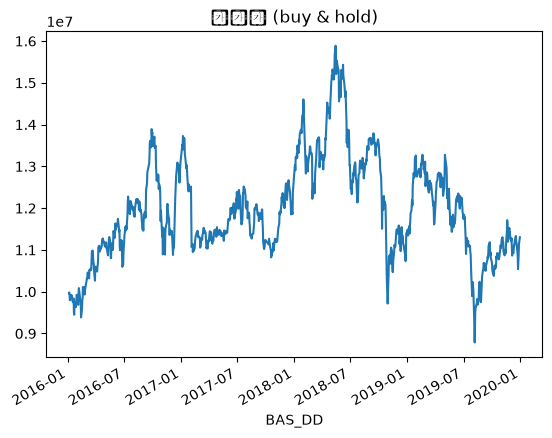

In [10]:
ser_buyhold.plot(title="무손절 (buy & hold)")
print(ser_buyhold.iloc[-1])   # final portfolio value, end of 2019

In [11]:
# Step 4: Selling

# sell_schedule = {"036890": pd.Timestamp("2017-06-30")}
sell_schedule = {}

holdings = pd.Series(per_stock, index=basket.columns)
cash = 0

records = []
for date in dates:
    # mark-to-market the holdings
    holdings = holdings * (1 + basket.loc[date] / 100)

    # sell
    to_sell = [s for s, d in sell_schedule.items() if d == date]
    for s in to_sell:
        proceeds = holdings[s]
        sell_cost = proceeds * COST_RATE
        cash += proceeds - sell_cost
        holdings[s] = 0 # gone; from now it sits in cash, not the market
    # record W
    W = holdings.sum() + cash
    records.append(W)

ser_sell = pd.Series(data=records, index=dates)

In [12]:
# Step 5: 현금일별수익률
holdings = pd.Series(per_stock, index=basket.columns)
cash = 0

# testing
sell_schedule = {"036890": pd.Timestamp("2017-06-30")}

records = []
for date in dates:
    # update cash with daily interest
    cash = cash * (1 + CASH_DAILY_RATE)

    # mark-to-market the holdings
    holdings = holdings * (1 + basket.loc[date] / 100)

    # process sells
    to_sell = [s for s, d in sell_schedule.items() if d == date]
    for s in to_sell:
        proceeds = holdings[s]
        sell_cost = proceeds * COST_RATE
        cash += proceeds - sell_cost
        holdings[s] = 0 # gone; from now it sits in cash, not the market

    # record W
    W = holdings.sum() + cash
    print(f"{date}: {W:,.2f}")
    records.append(W)

ser_sell_cash = pd.Series(data=records, index=dates)

2016-01-04 00:00:00: 9,958,374.96
2016-01-05 00:00:00: 9,983,004.13
2016-01-06 00:00:00: 9,942,852.25
2016-01-07 00:00:00: 9,796,473.60
2016-01-08 00:00:00: 9,867,164.39
2016-01-11 00:00:00: 9,911,366.73
2016-01-12 00:00:00: 9,885,045.17
2016-01-13 00:00:00: 9,914,795.90
2016-01-14 00:00:00: 9,835,536.03
2016-01-15 00:00:00: 9,779,806.18
2016-01-18 00:00:00: 9,745,586.29
2016-01-19 00:00:00: 9,837,255.42
2016-01-20 00:00:00: 9,499,003.62
2016-01-21 00:00:00: 9,448,955.49
2016-01-22 00:00:00: 9,676,984.01
2016-01-25 00:00:00: 9,746,486.26
2016-01-26 00:00:00: 9,630,029.00
2016-01-27 00:00:00: 9,708,127.52
2016-01-28 00:00:00: 9,830,368.70
2016-01-29 00:00:00: 9,927,727.87
2016-02-01 00:00:00: 9,867,370.73
2016-02-02 00:00:00: 9,730,306.53
2016-02-03 00:00:00: 9,686,106.54
2016-02-04 00:00:00: 9,976,746.46
2016-02-05 00:00:00: 10,085,951.64
2016-02-11 00:00:00: 9,709,642.00
2016-02-12 00:00:00: 9,384,650.35
2016-02-15 00:00:00: 9,579,480.91
2016-02-16 00:00:00: 9,795,979.43
2016-02-17 00

In [13]:
# step 6: putting everything together in a function
def run_strategy(basket, sell_schedule):    
    
    # 1. day-0 setup   ← your Step 2 code (compute n, investable, per_stock, holdings, cash)
    n = len(basket.columns) # number of stock codes listed
    investable = INITIAL_CASH / (1 + COST_RATE)

    # 종목별 매수금액 
    per_stock = investable / n

    # 최초 매수거래비용
    entry_cost = investable * COST_RATE # ~ 9,990.0

    # 현금 잔액 
    cash = INITIAL_CASH - investable - entry_cost # should land on 0

    # 보유가치
    holdings = pd.Series(data=per_stock, index=basket.columns)

    # 2. daily loop  (dates, the loop, record W)

    # get the days to walk
    dates = basket.index[basket.index >= '2016-01-04']  # start from the first trading day of 2016

    records = []
    for date in dates:
        # update cash with daily interest
        cash = cash * (1 + CASH_DAILY_RATE)

        # mark-to-market the holdings
        holdings = holdings * (1 + basket.loc[date] / 100)

        # process sells
        to_sell = [s for s, d in sell_schedule.items() if d == date]
        for s in to_sell:
            proceeds = holdings[s]
            sell_cost = proceeds * COST_RATE
            cash += proceeds - sell_cost
            holdings[s] = 0 # gone; from now it sits in cash, not the market

        # record W
        W = holdings.sum() + cash
        records.append(W)
    ser_sell_cash = pd.Series(data=records, index=dates)
    return ser_sell_cash


In [14]:
run_strategy(basket, {}).equals(ser_buyhold)


True

In [15]:
run_strategy(basket, {"036890": pd.Timestamp("2017-06-30")}).equals(ser_sell_cash)

False

In [16]:
print(basket.head(5))

ISU_CD      010170  032620  036890  038070  050540  053660  059090  059210  \
BAS_DD                                                                       
2015-01-02    1.49    1.52    0.36    0.85    1.59   -2.50   -1.34    0.98   
2015-01-05    0.56    0.38   -1.42   -0.72    0.00    2.97    0.68    0.58   
2015-01-06    2.25    0.19   -1.08   -0.85   -0.26   -1.57    5.41    0.39   
2015-01-07   -1.10    0.00    0.18    3.41    0.26    1.07    3.85    0.19   
2015-01-08    0.56    0.56    1.09   -1.18    0.00   -1.85   -0.31    1.35   

ISU_CD      065060  065350  068790  082800  083650  089010  093190  096350  \
BAS_DD                                                                       
2015-01-02    3.65    1.09    2.52   -1.05   -1.30    6.63    4.25   -1.31   
2015-01-05    0.88   -0.65   -0.22    2.83   -1.75   -0.73   -0.45   -1.52   
2015-01-06   -0.44   -0.87   -2.47    4.12    0.45    1.25   -1.36    0.00   
2015-01-07   -0.44    0.66    2.07   -2.31   -0.89   -3.61    0

In [17]:
# 단순손절 backtest logic

# hardcoded start date
start = '2016-01-04'

cum = (1 + basket.loc[start:]/100).cumprod()
schedule = {}
for stock in cum.columns:
    col = cum[stock]
    mask = col <= 0.80
    if mask.any():
        schedule[stock] = mask[mask].index[0]

print(schedule)
print(len(schedule), "stocks triggered out of", len(cum.columns))

{'038070': Timestamp('2017-07-11 00:00:00'), '050540': Timestamp('2016-01-28 00:00:00'), '053660': Timestamp('2016-01-20 00:00:00'), '059090': Timestamp('2016-02-12 00:00:00'), '059210': Timestamp('2017-08-14 00:00:00'), '065060': Timestamp('2019-07-26 00:00:00'), '065350': Timestamp('2016-02-02 00:00:00'), '068790': Timestamp('2018-10-26 00:00:00'), '082800': Timestamp('2016-02-11 00:00:00'), '083650': Timestamp('2019-08-02 00:00:00'), '089010': Timestamp('2016-05-18 00:00:00'), '093190': Timestamp('2017-02-02 00:00:00'), '096350': Timestamp('2016-01-20 00:00:00'), '097800': Timestamp('2016-10-31 00:00:00'), '153460': Timestamp('2018-07-23 00:00:00')}
15 stocks triggered out of 18


In [18]:
buyhold_line  = run_strategy(basket, {})         # 무손절
stoploss_line = run_strategy(basket, schedule)   # 단순손절

/Users/jihaein/Desktop/fds_main/investment-evidence-system/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 47924 (\N{HANGUL SYLLABLE MU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/jihaein/Desktop/fds_main/investment-evidence-system/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/jihaein/Desktop/fds_main/investment-evidence-system/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51208 (\N{HANGUL SYLLABLE JEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/jihaein/Desktop/fds_main/investment-evidence-system/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(byte

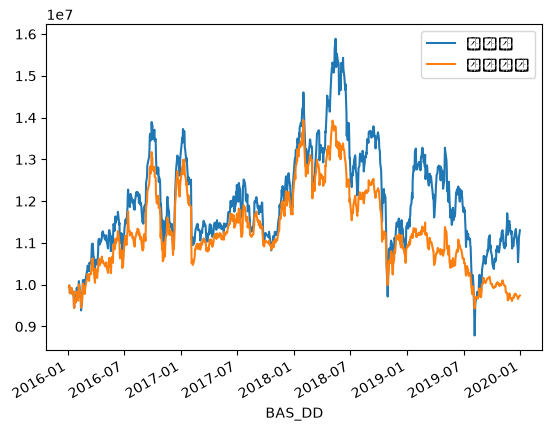

'\nX-axis = time (the dates)\nY-axis = portfolio value in won (W)\n\n무손절: blue \n단순손절: orange\n\n'

In [19]:
import matplotlib.pyplot as plt
buyhold_line.plot(label="무손절")
stoploss_line.plot(label="단순손절")
plt.legend(); plt.show()


"""
X-axis = time (the dates)
Y-axis = portfolio value in won (W)

무손절: blue 
단순손절: orange

"""

In [20]:
from models.seoseohi.pipeline import run_seoseohi, load_data

In [21]:
data = load_data()

portfolio = {
    "stock_code": "036890",
    "buy_date" : "2016-06-30"
}

result = run_seoseohi(data, portfolio, now_date = "2019-12-30")
print(result)
print(result["verdict"])


{'portfolio': {'stock_code': '036890', 'buy_date': '2016-06-30'}, 'now_date': '2019-12-30', 'verdict': 'No', 'dupont': {'score': 0, 'detail': {'stock_code': '036890', 'buy_date': '2016-06-30', 'now_date': '2019-12-30', 'dPM_adj_pp': np.float64(0.0), 'dATO_rel_pct': np.float64(89.45381997986952), 'score': 0, 'pm_detail': {'stock_code': '036890', 'buy_date': '2016-06-30', 'now_date': '2019-12-30', 'PM_adj_buy': np.float64(0.0), 'PM_adj_now': np.float64(0.0), 'dPM_adj_pp': np.float64(0.0), 'fs_div_flag': False, 'basis_buy': 'KSIC 29 (n=3)', 'basis_now': 'KSIC 29 (n=3)', 'note': None}, 'ato_detail': {'stock_code': '036890', 'buy_date': '2016-06-30', 'now_date': '2019-12-30', 'ATO_rel_buy': np.float64(1.077738011385474), 'ATO_rel_now': np.float64(2.0418158319448616), 'dATO_rel_pct': np.float64(89.45381997986952), 'note': None}, 'delisted': False, 'delisted_in_window': False}}, 'fscore': {'score': 1, 'detail': {'stock_code': '036890', 'buy_date': '2016-06-30', 'eval_date': '2019-12-30', 'f_s

In [22]:
eval_dates = pd.date_range("2016-06-30", "2019-12-30", freq="Q")

for date in eval_dates:
    result = run_seoseohi(data, {"stock_code": "053660", "buy_date": "2016-06-30"}, date.strftime("%Y-%m-%d"))
    print(date, result["verdict"]) 

2016-06-30 00:00:00 No
2016-09-30 00:00:00 유보
2016-12-31 00:00:00 주의
2017-03-31 00:00:00 주의
2017-06-30 00:00:00 주의
2017-09-30 00:00:00 주의
2017-12-31 00:00:00 주의
2018-03-31 00:00:00 주의
2018-06-30 00:00:00 No
2018-09-30 00:00:00 주의
2018-12-31 00:00:00 주의


/var/folders/rs/_8vt9fhj4wz7_b908j1m2bxr0000gn/T/ipykernel_83686/1095875331.py:1: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  eval_dates = pd.date_range("2016-06-30", "2019-12-30", freq="Q")


2019-03-31 00:00:00 주의
2019-06-30 00:00:00 No
2019-09-30 00:00:00 주의


In [23]:
buy_date = "2016-06-30"
seoseohi_schedule = {}
grid = load_daily_price()

eval_dates = pd.date_range("2016-06-30", "2019-12-30", freq="Q")

for stock in grid.columns:
    portfolio = {"stock_code": stock, "buy_date": buy_date}
    for now_date in eval_dates:
        verdict = run_seoseohi(data, portfolio, now_date.strftime("%Y-%m-%d"))["verdict"]
        print(stock, now_date.date(), verdict)        # ← see every call
        if verdict.startswith("Yes") or verdict == "주의":
            seoseohi_schedule[stock] = now_date
            break

/var/folders/rs/_8vt9fhj4wz7_b908j1m2bxr0000gn/T/ipykernel_83686/1941802824.py:5: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  eval_dates = pd.date_range("2016-06-30", "2019-12-30", freq="Q")


010170 2016-06-30 No
010170 2016-09-30 No
010170 2016-12-31 No
010170 2017-03-31 No
010170 2017-06-30 No
010170 2017-09-30 No
010170 2017-12-31 No
010170 2018-03-31 No
010170 2018-06-30 No
010170 2018-09-30 No
010170 2018-12-31 No
010170 2019-03-31 No
010170 2019-06-30 주의
032620 2016-06-30 No
032620 2016-09-30 유보
032620 2016-12-31 유보
032620 2017-03-31 No
032620 2017-06-30 주의
036890 2016-06-30 No
036890 2016-09-30 No
036890 2016-12-31 No
036890 2017-03-31 No
036890 2017-06-30 No
036890 2017-09-30 No
036890 2017-12-31 No
036890 2018-03-31 No
036890 2018-06-30 No
036890 2018-09-30 No
036890 2018-12-31 No
036890 2019-03-31 No
036890 2019-06-30 No
036890 2019-09-30 No
038070 2016-06-30 No
038070 2016-09-30 주의
050540 2016-06-30 No
050540 2016-09-30 No
050540 2016-12-31 No
050540 2017-03-31 No
050540 2017-06-30 No
050540 2017-09-30 No
050540 2017-12-31 No
050540 2018-03-31 No
050540 2018-06-30 유보
050540 2018-09-30 No
050540 2018-12-31 No
050540 2019-03-31 No
050540 2019-06-30 No
050540 2019-0

In [24]:
print(seoseohi_schedule)
print(len(seoseohi_schedule), "of", len(grid.columns), "triggered")

{'010170': Timestamp('2019-06-30 00:00:00'), '032620': Timestamp('2017-06-30 00:00:00'), '038070': Timestamp('2016-09-30 00:00:00'), '052270': Timestamp('2016-09-30 00:00:00'), '053660': Timestamp('2016-12-31 00:00:00'), '059210': Timestamp('2016-09-30 00:00:00'), '065060': Timestamp('2017-03-31 00:00:00'), '065350': Timestamp('2019-03-31 00:00:00'), '068790': Timestamp('2017-12-31 00:00:00'), '082800': Timestamp('2016-09-30 00:00:00'), '083650': Timestamp('2019-03-31 00:00:00'), '089010': Timestamp('2016-09-30 00:00:00'), '093190': Timestamp('2016-09-30 00:00:00'), '096350': Timestamp('2016-09-30 00:00:00'), '097800': Timestamp('2016-09-30 00:00:00'), '153460': Timestamp('2017-06-30 00:00:00')}
16 of 19 triggered


In [25]:
print(seoseohi_schedule["053660"])     # expect 2016-12-31

2016-12-31 00:00:00


In [26]:
print("036890" in seoseohi_schedule)     # expect False

False


In [27]:
seoseohi_line = run_strategy(grid, seoseohi_schedule)

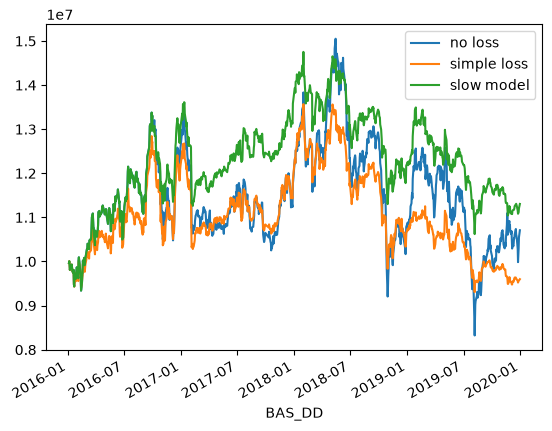

'\nBlue = 무손절 (plotted first)\nOrange = 단순손절 (plotted second)\nGreen = 서서히 (plotted third)\n'

In [28]:
cum = (1 + grid.loc["2016-01-04":] / 100).cumprod()
stoploss_schedule = {}
for stock in cum.columns:
    mask = cum[stock] <= 0.80
    if mask.any():
        stoploss_schedule[stock] = mask[mask].index[0]

buyhold   = run_strategy(grid, {})
stoploss  = run_strategy(grid, stoploss_schedule)
seoseohi  = run_strategy(grid, seoseohi_schedule)

buyhold.plot(label="no loss")
stoploss.plot(label="simple loss")
seoseohi.plot(label="slow model")
plt.legend(); plt.show()


"""
Blue = 무손절 (plotted first)
Orange = 단순손절 (plotted second)
Green = 서서히 (plotted third)
"""

In [33]:
returns = buyhold.pct_change().dropna()
cumret  = buyhold.iloc[-1] / buyhold.iloc[0] - 1

# 누적수익률 결과
print("누적수익률")
print(buyhold.iloc[-1]  / buyhold.iloc[0]  - 1)   # 무손절
print(stoploss.iloc[-1] / stoploss.iloc[0] - 1)   # 단순손절
print(seoseohi.iloc[-1] / seoseohi.iloc[0] - 1)   # 서서히

누적수익률
0.07463722932627825
-0.03666137534155656
0.13453206212135704


In [30]:
# MDD
def mdd(W):
    peak = W.cummax()
    dd   = 1 - W / peak
    return dd.max()

print ("MDD Analysis")
print("무손절 ", mdd(buyhold))
print("단순손절", mdd(stoploss))
print("서서히 ", mdd(seoseohi))

MDD Analysis
무손절  0.447043766424454
단순손절 0.3142257213360291
서서히  0.2800606211421176


In [31]:
def sortino(W):
    r = W.pct_change().dropna()
    downside = r.clip(upper=0)
    dd_down  = (downside**2).mean() ** 0.5
    return (r.mean() / dd_down) * (252 ** 0.5)

print ("sortino Analysis")
print("무손절 ", sortino(buyhold))
print("단순손절", sortino(stoploss))
print("서서히 ", sortino(seoseohi))

sortino Analysis
무손절  0.27658604590977054
단순손절 0.05868432108413114
서서히  0.37762442309158273


In [36]:
# Sharpe Ratio / Higher the Better Result
def sharpe(W):
    r = W.pct_change().dropna()
    return (r.mean() / r.std()) * (252 ** 0.5)

print("Sharpe Ratio")
print("무손절 ", sharpe(buyhold))
print("단순손절", sharpe(stoploss))
print("서서히 ", sharpe(seoseohi))

Sharpe Ratio
무손절  0.20346143962212077
단순손절 0.04176039136115943
서서히  0.26919414666740316


# Interpretation of Sharpe Ratio

Sharpe Ratio: measures the average return earned in excess of the risk-free rate per unit of total risk or volatility.

서서히모델 again wins relatively. The absolute value of sharpe ratio is pretty bad though.

The reason is:
- we are stress testing on 19 troubled, volatile KOSDAQ small-caps. Some of them are literally falling / delisting. That’s a basket that was deliberately chosen to stress-test whether the model catches deterioration, not to be a good portfolio. Troubled small-caps are low-return and high-volatility by nature → low Sharpe for everyone. A boring index fund would crush all three of these on Sharpe.

In [38]:
# 현금대체효과

cash_effect = {}
for stock, sell_date in seoseohi_schedule.items():
    future = grid.loc[sell_date:, stock].dropna()   # the stock's returns AFTER you sold
    R_hold = (1 + future / 100).prod() - 1           # what holding would have earned
    n_days = len(future)
    R_cash = (1 + CASH_DAILY_RATE) ** n_days - 1      # what cash earned over the same days
    cash_effect[stock] = R_cash - R_hold             # B

for s, b in sorted(cash_effect.items(), key=lambda x: -x[1]):
    print(s, f"{b:+.1%}")

052270 +92.1%
053660 +86.9%
059210 +52.8%
065060 +49.4%
097800 +49.1%
038070 +41.5%
153460 +35.9%
083650 +31.5%
096350 +29.3%
093190 +28.4%
010170 +26.8%
068790 +20.0%
065350 +14.8%
082800 -41.6%
032620 -62.5%
089010 -158.3%
